In [1]:
import os
import warnings

warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import seaborn as sns

import google.auth
from google.cloud import bigquery

In [ ]:

# SECTION 1: SETUP & CONFIGURATION

plt.rcParams.update({
    "figure.figsize": (14, 6),
    "figure.facecolor": "white",
    "figure.dpi": 100,

    "font.family": "sans-serif",
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlepad": 15,
    "axes.labelsize": 11,
    "axes.labelweight": "bold",

    "axes.facecolor": "#F8F9FA",
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.color": "#E0E0E0",
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    "xtick.labelsize": 10,
    "ytick.labelsize": 10,

    "legend.fontsize": 10,
    "legend.framealpha": 0.9,

    "savefig.bbox": "tight",
    "savefig.dpi": 150,
})

COLORS = {
    "primary": "#2196F3",    # Blue: main metric
    "secondary": "#FF9800",  # Orange: comparison
    "success": "#4CAF50",    # Green: positive
    "danger": "#F44336",     # Red: negative / alert
    "neutral": "#9E9E9E",    # Gray: reference
    "purple": "#9C27B0",     # Purple: accent
    "teal": "#009688",       # Teal: secondary metric
}

PALETTE_5 = [
    "#2196F3",
    "#4CAF50",
    "#FF9800",
    "#F44336",
    "#9C27B0",
]

PROJECT_ID = "olist-ecommerce-analytics-1"

MART_DATASET = f"{PROJECT_ID}.olist_mart"
REPORTING_DATASET = f"{PROJECT_ID}.olist_reporting"

def get_bq_client(project_id: str) -> bigquery.Client:

    credentials, _ = google.auth.default(
        scopes=["https://www.googleapis.com/auth/cloud-platform"]
    )

    return bigquery.Client(
        project=project_id,
        credentials=credentials,
    )

def run_query(
    client: bigquery.Client,
    query: str,
) -> pd.DataFrame:

    query_job = client.query(query)

    return query_job.result().to_dataframe()

client = get_bq_client(PROJECT_ID)

print("BigQuery client initialized successfully")


BigQuery client initialized successfully
Project: olist-ecommerce-analytics-1
Mart dataset: olist-ecommerce-analytics-1.olist_mart
Reporting dataset: olist-ecommerce-analytics-1.olist_reporting


In [5]:
query_orders = f"""
    SELECT
        order_id,
        customer_unique_id,
        order_status,
        purchase_date,
        purchase_year,
        purchase_month,
        purchase_year_month,
        purchase_year_quarter,
        purchase_day_of_week,
        is_revenue_generating,
        is_delivered,
        is_ontime_delivery,
        is_order_date_anomaly,
        purchase_to_delivery_days,
        delivery_vs_estimated_days,
        total_price,
        total_freight_value,
        total_gmv,
        item_count,
        primary_payment_type,
        max_installments,
        used_voucher,
        review_score,
        review_sentiment,
        customer_type,
        rfm_segment,
        clv_tier
    FROM `{MART_DATASET}.fact_orders`
"""
df_orders = run_query(client, query_orders)
df_orders['purchase_date'] = pd.to_datetime(df_orders['purchase_date'])
print(f"fact_orders loaded:      {len(df_orders):>8,} rows")

df_delivered = df_orders[
    df_orders['is_revenue_generating'] == True
].copy()

fact_orders loaded:        98,666 rows


In [12]:
numeric_columns = [
    "total_price",
    "total_freight_value",
    "total_gmv",
]

for col in numeric_columns:
    df_delivered[col] = pd.to_numeric(
        df_delivered[col],
        errors="raise"
    )

df_delivered["purchase_date"] = pd.to_datetime(
    df_delivered["purchase_date"],
    errors="raise"
)

integer_columns = [
    "purchase_year",
    "purchase_month",
    "purchase_day_of_week",
    "purchase_to_delivery_days",
    "delivery_vs_estimated_days",
    "item_count",
    "max_installments",
    "review_score",
]

for col in integer_columns:
    df_delivered[col] = df_delivered[col].astype("Int64")

boolean_columns = [
    "is_revenue_generating",
    "is_delivered",
    "is_ontime_delivery",
    "is_order_date_anomaly",
    "used_voucher",
]

for col in boolean_columns:
    df_delivered[col] = df_delivered[col].astype("boolean")

print(df_delivered.dtypes)

df_delivered.info()


order_id                                str
customer_unique_id                      str
order_status                            str
purchase_date                 datetime64[s]
purchase_year                         Int64
purchase_month                        Int64
purchase_year_month                     str
purchase_year_quarter                   str
purchase_day_of_week                  Int64
is_revenue_generating               boolean
is_delivered                        boolean
is_ontime_delivery                  boolean
is_order_date_anomaly               boolean
purchase_to_delivery_days             Int64
delivery_vs_estimated_days            Int64
total_price                         float64
total_freight_value                 float64
total_gmv                           float64
item_count                            Int64
primary_payment_type                    str
max_installments                      Int64
used_voucher                        boolean
review_score                    

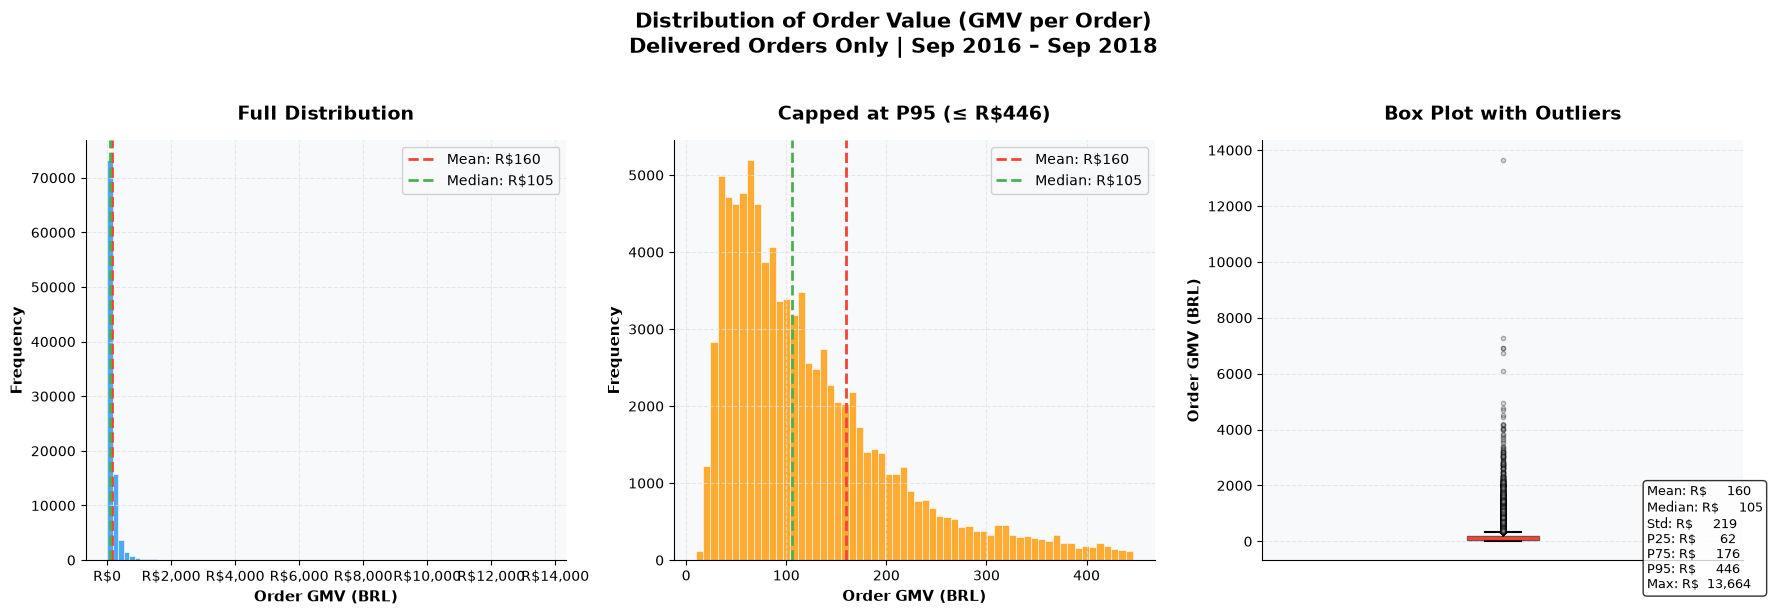


 ORDER VALUE STATISTICS:
 Count: 96,478
 Mean: R$159.83
 Median: R$105.28
 Std Dev: R$218.79
 Skewness: 9.368 (Right-skewed)
 P90: R$305.92
 P95: R$446.23
 P99: R$1,052.39

 Mean (R$160) > Median (R$105)


In [ ]:
# 2.1 DISTRIBUSI ORDER VALUE (GMV per Order)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle(
    'Distribution of Order Value (GMV per Order)\n'
    'Delivered Orders Only | Sep 2016 – Sep 2018',
    fontsize=15, fontweight='bold', y=1.02
)

gmv_data = df_delivered['total_gmv'].dropna()

# Plot 1: Histogram (full range)
ax1 = axes[0]
ax1.hist(
    gmv_data,
    bins=80,
    color=COLORS['primary'],
    alpha=0.8,
    edgecolor='white',
    linewidth=0.5
)
ax1.set_xlabel('Order GMV (BRL)')
ax1.set_ylabel('Frequency')
ax1.set_title('Full Distribution')
ax1.axvline(
    gmv_data.mean(),
    color=COLORS['danger'],
    linestyle='--',
    linewidth=2,
    label=f"Mean: R${gmv_data.mean():.0f}"
)
ax1.axvline(
    gmv_data.median(),
    color=COLORS['success'],
    linestyle='--',
    linewidth=2,
    label=f"Median: R${gmv_data.median():.0f}"
)
ax1.legend()
ax1.xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'R${x:,.0f}')
)

# Plot 2: Histogram (capped at P95 untuk visibility)
ax2 = axes[1]
p95 = gmv_data.quantile(0.95)
gmv_trimmed = gmv_data[gmv_data <= p95]
ax2.hist(
    gmv_trimmed,
    bins=60,
    color=COLORS['secondary'],
    alpha=0.8,
    edgecolor='white',
    linewidth=0.5
)
ax2.set_xlabel('Order GMV (BRL)')
ax2.set_ylabel('Frequency')
ax2.set_title(f'Capped at P95 (≤ R${p95:,.0f})')
ax2.axvline(
    gmv_data.mean(),
    color=COLORS['danger'],
    linestyle='--',
    linewidth=2,
    label=f"Mean: R${gmv_data.mean():.0f}"
)
ax2.axvline(
    gmv_data.median(),
    color=COLORS['success'],
    linestyle='--',
    linewidth=2,
    label=f"Median: R${gmv_data.median():.0f}"
)
ax2.legend()

# Plot 3: Box Plot dengan outlier detail
ax3 = axes[2]
bp = ax3.boxplot(
    gmv_data,
    vert=True,
    patch_artist=True,
    boxprops=dict(facecolor=COLORS['primary'], alpha=0.6),
    medianprops=dict(color=COLORS['danger'], linewidth=2.5),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5),
    flierprops=dict(
        marker='o', markersize=3,
        markerfacecolor=COLORS['neutral'], alpha=0.3
    )
)
ax3.set_ylabel('Order GMV (BRL)')
ax3.set_title('Box Plot with Outliers')

stats_text = (
    f"Mean: R${gmv_data.mean():>8,.0f}\n"
    f"Median: R${gmv_data.median():>8,.0f}\n"
    f"Std: R${gmv_data.std():>8,.0f}\n"
    f"P25: R${gmv_data.quantile(.25):>8,.0f}\n"
    f"P75: R${gmv_data.quantile(.75):>8,.0f}\n"
    f"P95: R${gmv_data.quantile(.95):>8,.0f}\n"
    f"Max: R${gmv_data.max():>8,.0f}"
)
ax3.text(
    1.3, gmv_data.median(),
    stats_text,
    fontsize=9,
    verticalalignment='center',
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8)
)
ax3.set_xticks([])

plt.tight_layout()
plt.savefig('../assets/eda/01_order_value_distribution.png')
plt.show()

skewness = gmv_data.skew()
print(f"\n ORDER VALUE STATISTICS:")
print(f" Count: {len(gmv_data):,}")
print(f" Mean: R${gmv_data.mean():,.2f}")
print(f" Median: R${gmv_data.median():,.2f}")
print(f" Std Dev: R${gmv_data.std():,.2f}")
print(f" Skewness: {skewness:.3f} "
      f"({'Right-skewed' if skewness > 0 else 'Left-skewed'})")
print(f" P90: R${gmv_data.quantile(.90):,.2f}")
print(f" P95: R${gmv_data.quantile(.95):,.2f}")
print(f" P99: R${gmv_data.quantile(.99):,.2f}")
print(f"\n Mean (R${gmv_data.mean():.0f}) > Median (R${gmv_data.median():.0f})")